# CH 421 Technical Computing 3

Option 2 (gen-AI), and the bonus question.

Titration of 25.00 mL of 0.01 M hydrazine (pK<sub>b</sub> = 5.9, a weak base) with 0.02 M HCl (strong acid): the titration curve, the equivalence volume, the pH before any acid is added, and the pH at the equivalence point.

## 1. Gen-AI used and prompts

I used Claude Opus 5.5 from Anthropic (model ID `claude-opus-5-5`), through Claude Code in the Claude desktop app, on November 25, 2026. Claude wrote and ran all of the code in this notebook.

My first prompt went in with a screenshot of the Canvas instructions (the Option 2 and bonus text; the bonus question is copied into its cell below):

> Please help me write the code for CH 421's Technical Computing 3 assignment. Both Technical computing 1 and 2 are in the College repo and may be referenced for a better idea of how to write the script for the Technical computing 3 assignment. I will upload the criteria in a screenshot for you to reference for instructions. We are completing option 2 as well as the bonus. I will read through the ipynb file and provide feedback. Do not complete the writing portions, as those are for me to write without AI input.
>
> If you have questions ask me, otherwise please begin.

Before writing anything, Claude read my Technical Computing 1 and 2 notebooks so this one would follow the same layout, and the lecture slides on weak base titrations (3-3) and activities (3-2).

## 2. Code

### Importing packages

In [1]:
import numpy as np                  # math functions, arrays, and np.log10 for the pH
import matplotlib.pyplot as plt     # this package is used for making plots
from scipy.optimize import brentq   # finds where a function crosses zero, used to solve the charge balance

print('packages imported')

packages imported


### The values given in the problem

Hydrazine, N<sub>2</sub>H<sub>4</sub>, is the weak base B. Its conjugate acid is the hydrazinium ion, N<sub>2</sub>H<sub>5</sub><sup>+</sup> (BH<sup>+</sup>).

In [2]:
V_base = 25.00     # mL of hydrazine solution in the flask
C_base = 0.01      # M hydrazine, N2H4, the weak base (analyte)
C_acid = 0.02      # M HCl, the strong acid (titrant)
pKb    = 5.9       # hydrazine, given
Kw     = 1.0E-14   # water at 25 C

Kb  = 10**(-pKb)   # N2H4 + H2O <=> N2H5+ + OH-
Ka  = Kw/Kb        # N2H5+ <=> N2H4 + H+, the acid constant of the conjugate acid
pKa = -np.log10(Ka)

print('Kb  =', Kb)
print('Ka  =', Ka)
print('pKa =', round(pKa, 2), '(of N2H5+)')

Kb  = 1.2589254117941661e-06
Ka  = 7.943282347242822e-09
pKa = 8.1 (of N2H5+)


### Equivalence volume

HCl is a strong acid, so the titration reaction N<sub>2</sub>H<sub>4</sub> + H<sup>+</sup> &rarr; N<sub>2</sub>H<sub>5</sub><sup>+</sup> goes to completion, one H<sup>+</sup> per hydrazine. The equivalence point is where the moles of HCl added equal the moles of hydrazine in the flask.

In [3]:
mol_base = C_base*V_base/1000    # mol of hydrazine in the flask (mL to L)
Ve = mol_base/C_acid*1000        # mL of HCl that holds the same number of moles (L to mL)

print('moles of hydrazine =', mol_base, 'mol')
print('equivalence volume, Ve =', round(Ve, 2), 'mL')

moles of hydrazine = 0.00025 mol
equivalence volume, Ve = 12.5 mL


### A function for the pH after any volume of HCl

Instead of switching formulas between regions of the curve, this function solves the charge balance, which holds at every point of the titration:

[H<sup>+</sup>] + [N<sub>2</sub>H<sub>5</sub><sup>+</sup>] = [OH<sup>&minus;</sup>] + [Cl<sup>&minus;</sup>]

The total hydrazine (N<sub>2</sub>H<sub>4</sub> + N<sub>2</sub>H<sub>5</sub><sup>+</sup>) and the Cl<sup>&minus;</sup> from the HCl are both known from the volumes, after dilution. For a guessed pH, the fraction of hydrazine that is protonated is [H<sup>+</sup>]/([H<sup>+</sup>] + K<sub>a</sub>), and [OH<sup>&minus;</sup>] = K<sub>w</sub>/[H<sup>+</sup>]. `brentq` tries pH values between 0 and 14 until the positive and negative charges balance.

In [4]:
def titration_pH(Va):
    '''pH after Va mL of HCl has been added, from the charge balance.'''
    V_total = V_base + Va                 # mL in the flask
    B_total = C_base*V_base/V_total       # M of N2H4 + N2H5+, diluted by the added acid
    Cl      = C_acid*Va/V_total           # M chloride from the HCl, a spectator ion

    def charge_balance(pH):
        H  = 10**(-pH)                    # M H+
        OH = Kw/H                         # M OH-
        BH = B_total*H/(H + Ka)           # M N2H5+, the protonated fraction of the hydrazine
        return H + BH - OH - Cl           # positive charge minus negative charge, zero at the right pH

    return brentq(charge_balance, 0, 14)  # the pH between 0 and 14 where the charge balance is zero

### pH before any acid is added

In [5]:
pH_initial = titration_pH(0)

print('pH before any acid is added =', round(pH_initial, 2))
print('[OH-] =', 10**(pH_initial - 14), 'M')

pH before any acid is added = 10.05
[OH-] = 0.00011157419344702953 M


### pH at the equivalence point

At V<sub>e</sub> all of the hydrazine has become N<sub>2</sub>H<sub>5</sub><sup>+</sup>, a weak acid, diluted to 25.00/(25.00 + V<sub>e</sub>) of its first concentration.

In [6]:
pH_equivalence = titration_pH(Ve)
F_prime = C_base*V_base/(V_base + Ve)    # M N2H5+ at the equivalence point

print("formal concentration of N2H5+ at Ve, F' =", round(F_prime, 5), 'M')
print('pH at the equivalence point (', round(Ve, 2), 'mL ) =', round(pH_equivalence, 2))

formal concentration of N2H5+ at Ve, F' = 0.00667 M
pH at the equivalence point ( 12.5 mL ) = 5.14


### pH at the volumes listed in Option 1

Option 2 doesn't ask for these, but they're points on the curve and are used in the checks in section 4.

In [7]:
volumes = np.array([0, 1, 4, 6, 8, 10, 12, Ve, 13, 14, 16, 18, 20])   # mL of HCl
pH_at_volumes = np.array([titration_pH(v) for v in volumes])

print('HCl added (mL)    pH')
for v, p in zip(volumes, pH_at_volumes):
    print('%10.2f      %6.2f' % (v, p))

HCl added (mL)    pH
      0.00       10.05
      1.00        9.15
      4.00        8.43
      6.00        8.13
      8.00        7.85
     10.00        7.50
     12.00        6.72
     12.50        5.14
     13.00        3.58
     14.00        3.11
     16.00        2.77
     18.00        2.59
     20.00        2.48


### Titration curve

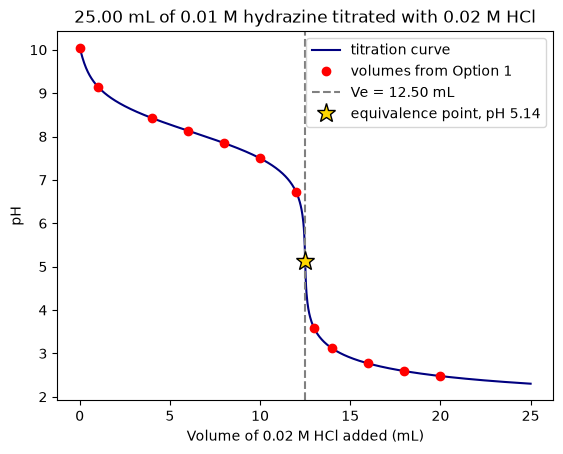

In [8]:
V_curve  = np.linspace(0, 25, 1001)                     # mL of HCl, 0.025 mL apart
pH_curve = np.array([titration_pH(v) for v in V_curve])

plt.plot(V_curve, pH_curve, color = 'navy', label = 'titration curve')
plt.plot(volumes, pH_at_volumes, linestyle = '', marker = 'o', color = 'red', label = 'volumes from Option 1')
plt.axvline(Ve, color = 'gray', linestyle = '--', label = 'Ve = %.2f mL' % Ve)
plt.plot(Ve, pH_equivalence, linestyle = '', marker = '*', markersize = 14, color = 'gold',
         markeredgecolor = 'black', label = 'equivalence point, pH %.2f' % pH_equivalence)

plt.xlabel('Volume of 0.02 M HCl added (mL)')
plt.ylabel('pH')
plt.title('25.00 mL of 0.01 M hydrazine titrated with 0.02 M HCl')
plt.legend()
plt.show()

In [9]:
print('equivalence volume          =', round(Ve, 2), 'mL')
print('pH before any acid is added =', round(pH_initial, 2))
print('pH at the equivalence point =', round(pH_equivalence, 2))

equivalence volume          = 12.5 mL
pH before any acid is added = 10.05
pH at the equivalence point = 5.14


## 3. Differences from the method shown in the tutorial

The method from lecture splits the curve into four regions and uses a different formula in each one:

1. **No acid added:** a weak base problem, x<sup>2</sup>/(F &minus; x) = K<sub>b</sub>, solved for x = [OH<sup>&minus;</sup>].
2. **Before V<sub>e</sub>:** a buffer of N<sub>2</sub>H<sub>4</sub> and N<sub>2</sub>H<sub>5</sub><sup>+</sup>, with Henderson-Hasselbalch, pH = pK<sub>a</sub> + log((V<sub>e</sub> &minus; V<sub>a</sub>)/V<sub>a</sub>).
3. **At V<sub>e</sub>:** a weak acid problem for N<sub>2</sub>H<sub>5</sub><sup>+</sup>, x<sup>2</sup>/(F' &minus; x) = K<sub>a</sub>.
4. **After V<sub>e</sub>:** the excess H<sup>+</sup> from the HCl, diluted.

The Clanker's script doesn't use any regions. It writes one equation, the charge balance, that holds at every volume, and has the computer solve it. So the same function gives the pH before any acid, in the buffer region, at V<sub>e</sub>, and past it, and it doesn't need an `if` statement to choose a formula or the quadratic formula.

Functions and syntax that weren't in Technical Computing 1 or 2:

- `brentq`, from `scipy.optimize`, finds where a function crosses zero. It's given a function and two values on either side of the answer (pH 0 and 14 here), and narrows the range until it finds the pH where the charge balance equals zero. This replaces solving the quadratic by hand.
- `def` makes a new function. `titration_pH(Va)` takes a volume and returns a pH, so the whole curve is one line, `[titration_pH(v) for v in V_curve]`.
- A function inside a function: `charge_balance(pH)` is defined inside `titration_pH`, so it can use that volume's concentrations.
- `[... for v in ...]` is a list comprehension, a one-line `for` loop that makes a list, which `np.array` turns into an array.
- `zip(volumes, pH_at_volumes)` steps through two arrays together in the printed table.
- `plt.axvline` draws a vertical line across the plot, used to mark V<sub>e</sub>.
- In the checks, `np.gradient` takes the slope of the curve point by point, `np.argmax` finds where it's steepest, and `np.max(np.abs(...))` finds the largest difference between the two methods.

## 4. Why the AI-generated answer is reasonable

**The equivalence volume.** 25.00 mL &times; 0.01 M = 0.25 mmol of hydrazine, and 0.25 mmol / 0.02 M = 12.5 mL. The acid is twice as concentrated as the base, so V<sub>e</sub> should be half of 25 mL, and it is.

**The starting pH.** Hydrazine is a weak base at 0.01 M, so the pH should be above 7 but well below the pH 12 of 0.01 M NaOH. The quick estimate [OH<sup>&minus;</sup>] &asymp; &radic;(K<sub>b</sub>F) = &radic;(10<sup>&minus;5.9</sup> &times; 0.01) = 1.1 &times; 10<sup>&minus;4</sup> M gives pOH 3.95 and pH 10.05, which matches the code.

**The pH at the equivalence point.** At V<sub>e</sub> the flask holds N<sub>2</sub>H<sub>5</sub><sup>+</sup>, a weak acid, so the pH has to be below 7. With F' = 0.00667 M, &radic;(K<sub>a</sub>F') = 7.3 &times; 10<sup>&minus;6</sup> M gives pH 5.14, the code's value.

**The shape of the curve.** It starts at pH 10, drops slowly through the buffer region, falls steeply at 12.5 mL, and levels off near pH 2.5. At half of V<sub>e</sub>, 6.25 mL, the buffer has equal N<sub>2</sub>H<sub>4</sub> and N<sub>2</sub>H<sub>5</sub><sup>+</sup>, so the pH should equal pK<sub>a</sub> = 14 &minus; 5.9 = 8.1, and the code gives 8.10. The steepest point on the computed curve falls at 12.5 mL, on V<sub>e</sub>. The checks below show these numbers.

**Comparing with the lecture method.** The cell below also computes every point the region-by-region way. The two agree to within 0.01 pH at every volume. The largest gap, 0.009, is at 1 mL. There Henderson-Hasselbalch assumes [N<sub>2</sub>H<sub>5</sub><sup>+</sup>] comes only from the HCl added, but with so little acid, the hydrazine's own reaction with water adds a few percent more N<sub>2</sub>H<sub>5</sub><sup>+</sup>, which the charge balance includes. Exactly at V<sub>e</sub> and past it the two agree to 0.001. 

In [10]:
# Check 1: the region-by-region method from lecture, at the same volumes
def region_pH(Va):
    if Va == 0:                                            # region 1: weak base
        F = C_base
        x = (-Kb + np.sqrt(Kb**2 + 4*Kb*F))/2             # quadratic formula for x^2/(F - x) = Kb, x = [OH-]
        return 14 + np.log10(x)                           # pH = 14 - pOH
    elif Va < Ve:                                          # region 2: buffer of N2H4 and N2H5+
        return pKa + np.log10((Ve - Va)/Va)               # Henderson-Hasselbalch
    elif Va == Ve:                                         # region 3: weak acid N2H5+
        F = C_base*V_base/(V_base + Ve)
        x = (-Ka + np.sqrt(Ka**2 + 4*Ka*F))/2             # x^2/(F' - x) = Ka, x = [H+]
        return -np.log10(x)
    else:                                                  # region 4: excess strong acid, diluted
        return -np.log10(C_acid*(Va - Ve)/(V_base + Va))

region_values = np.array([region_pH(v) for v in volumes])
print('HCl (mL)   charge balance   lecture method   difference')
for v, a, b in zip(volumes, pH_at_volumes, region_values):
    print('%8.2f   %14.3f   %14.3f   %10.3f' % (v, a, b, round(a - b, 3) + 0.0))   # + 0.0 turns -0.000 into 0.000
print('largest difference =', round(np.max(np.abs(pH_at_volumes - region_values)), 3), 'pH units')
print()

# Check 2: at half of Ve, the pH should equal pKa of N2H5+
print('pH at Ve/2 = %.3f , pKa = %.3f' % (titration_pH(Ve/2), pKa))
print()

# Check 3: the steepest point of the curve should be at Ve
slope = np.gradient(pH_curve, V_curve)            # dpH/dV at each point
print('steepest point of the curve at', V_curve[np.argmax(np.abs(slope))], 'mL , Ve =', Ve, 'mL')
print()

# Check 4: quick square-root estimates for the starting and equivalence pH
print('starting pH from sqrt(Kb*F)       =', round(14 + np.log10(np.sqrt(Kb*C_base)), 2))
print("equivalence pH from sqrt(Ka*F')   =", round(-np.log10(np.sqrt(Ka*F_prime)), 2))

HCl (mL)   charge balance   lecture method   difference
    0.00           10.048           10.048        0.000
    1.00            9.152            9.161       -0.009
    4.00            8.427            8.427       -0.001
    6.00            8.134            8.135        0.000
    8.00            7.850            7.850        0.000
   10.00            7.498            7.498        0.000
   12.00            6.720            6.720        0.000
   12.50            5.138            5.138        0.000
   13.00            3.579            3.580        0.000
   14.00            3.114            3.114        0.000
   16.00            2.768            2.768        0.000
   18.00            2.592            2.592        0.000
   20.00            2.477            2.477        0.000
largest difference = 0.009 pH units

pH at Ve/2 = 8.100 , pKa = 8.100

steepest point of the curve at 12.5 mL , Ve = 12.5 mL

starting pH from sqrt(Kb*F)       = 10.05
equivalence pH from sqrt(Ka*F')   = 5.14


## Bonus question

What is the pH of a 100 mL solution containing 1.050 g NaHCO<sub>3</sub> and 9.274 g Na<sub>2</sub>CO<sub>3</sub>, accounting for nonidealities?

### Concentrations

This is a buffer of HCO<sub>3</sub><sup>&minus;</sup> and its conjugate base CO<sub>3</sub><sup>2&minus;</sup>, so the equilibrium that sets the pH is HCO<sub>3</sub><sup>&minus;</sup> &rlarr; H<sup>+</sup> + CO<sub>3</sub><sup>2&minus;</sup>, with pK<sub>2</sub> = 10.329 for carbonic acid (Harris, Appendix G, p. AP20).

In [11]:
mass_NaHCO3 = 1.050       # g
mass_Na2CO3 = 9.274       # g
V_solution  = 0.100       # L

FM_NaHCO3 = 84.01         # g/mol (Harris)
FM_Na2CO3 = 105.99        # g/mol (Harris)

C_HCO3 = mass_NaHCO3/FM_NaHCO3/V_solution    # M bicarbonate
C_CO3  = mass_Na2CO3/FM_Na2CO3/V_solution    # M carbonate
C_Na   = C_HCO3 + 2*C_CO3                     # M sodium, one from NaHCO3 and two from each Na2CO3

pK1 = 6.351               # carbonic acid, Harris Appendix G, at zero ionic strength and 25 C
pK2 = 10.329
K1, K2 = 10**(-pK1), 10**(-pK2)

print('[HCO3-] =', round(C_HCO3, 4), 'M')
print('[CO3 2-] =', round(C_CO3, 4), 'M')
print('[Na+]   =', round(C_Na, 4), 'M')

[HCO3-] = 0.125 M
[CO3 2-] = 0.875 M
[Na+]   = 1.875 M


### Ionic strength and activity coefficients

Ionic strength is &mu; = &frac12; &Sigma; c<sub>i</sub>z<sub>i</sub><sup>2</sup> over every ion (slide 3-2, 30). Activity coefficients come from the extended Debye-Hückel equation used in class (slide 3-2, 29; Harris Eq. 8-6, p. 173), with ion sizes from Harris Table 8-1: 450 pm for HCO<sub>3</sub><sup>&minus;</sup> and CO<sub>3</sub><sup>2&minus;</sup>, 900 pm for H<sup>+</sup>, and 350 pm for OH<sup>&minus;</sup>.

log &gamma; = &minus;0.51 z<sup>2</sup>&radic;&mu; / (1 + &alpha;&radic;&mu;/305)

With activities, Henderson-Hasselbalch becomes pH = pK<sub>2</sub> + log(&gamma;<sub>CO<sub>3</sub><sup>2&minus;</sup></sub>[CO<sub>3</sub><sup>2&minus;</sup>] / &gamma;<sub>HCO<sub>3</sub><sup>&minus;</sup></sub>[HCO<sub>3</sub><sup>&minus;</sup>]), where pH = &minus;log(&gamma;<sub>H<sup>+</sup></sub>[H<sup>+</sup>]) (slide 3-2, 33).

In [12]:
def gamma_debye_huckel(z, alpha, mu):
    '''Activity coefficient from the extended Debye-Huckel equation, alpha in pm, 25 C.'''
    return 10**(-0.51*z**2*np.sqrt(mu)/(1 + alpha*np.sqrt(mu)/305))

mu = 0.5*(C_Na*1**2 + C_HCO3*1**2 + C_CO3*2**2)    # H+ and OH- are far too dilute to matter

g_HCO3 = gamma_debye_huckel(1, 450, mu)
g_CO3  = gamma_debye_huckel(2, 450, mu)

pH_ideal    = pK2 + np.log10(C_CO3/C_HCO3)                     # ignoring activity
pH_activity = pK2 + np.log10(g_CO3*C_CO3/(g_HCO3*C_HCO3))      # with activity coefficients

print('ionic strength, mu =', round(mu, 3), 'M')
print('gamma(HCO3-)  =', round(g_HCO3, 3))
print('gamma(CO3 2-) =', round(g_CO3, 3))
print()
print('pH ignoring activities (ideal)  =', round(pH_ideal, 2))
print('pH with activity coefficients   =', round(pH_activity, 2))

ionic strength, mu = 2.75 M
gamma(HCO3-)  = 0.568
gamma(CO3 2-) = 0.104

pH ignoring activities (ideal)  = 11.17
pH with activity coefficients   = 10.44


### Check: the full equilibrium with activities

Henderson-Hasselbalch assumes the HCO<sub>3</sub><sup>&minus;</sup> and CO<sub>3</sub><sup>2&minus;</sup> don't react further. Some CO<sub>3</sub><sup>2&minus;</sup> does react with water to make HCO<sub>3</sub><sup>&minus;</sup> and OH<sup>&minus;</sup>, which changes the concentrations and the ionic strength a little. This cell solves the charge balance with K<sub>1</sub>, K<sub>2</sub>, and K<sub>w</sub> written in activities, then recalculates the ionic strength from the new concentrations and repeats until it stops changing (the circular calculation in Harris section 13-2).

In [13]:
def carbonate_pH(gammas):
    '''Solve the carbonate buffer with activities. gammas(mu) returns (H+, OH-, HCO3-, CO3 2-) coefficients.'''
    C_total = C_HCO3 + C_CO3                       # M of all carbonate forms
    mu_now = mu                                    # start from the simple ionic strength
    for i in range(100):
        gH, gOH, gHCO3, gCO3 = gammas(mu_now)

        def species(pH):
            aH = 10**(-pH)                         # activity of H+, since pH = -log(aH)
            H  = aH/gH
            OH = Kw/aH/gOH                         # Kw = aH*aOH
            r1 = K1/(aH*gHCO3)                     # [HCO3-]/[H2CO3]
            r2 = r1*K2*gHCO3/(aH*gCO3)             # [CO3 2-]/[H2CO3]
            HCO3 = C_total*r1/(1 + r1 + r2)
            CO3  = C_total*r2/(1 + r1 + r2)
            return H, OH, HCO3, CO3

        def charge_balance(pH):
            H, OH, HCO3, CO3 = species(pH)
            return C_Na + H - HCO3 - 2*CO3 - OH

        pH = brentq(charge_balance, 7, 14)
        H, OH, HCO3, CO3 = species(pH)
        mu_new = 0.5*(C_Na + H + HCO3 + 4*CO3 + OH)
        if abs(mu_new - mu_now) < 1E-10:           # ionic strength has stopped changing
            break
        mu_now = mu_new
    return pH, mu_now, HCO3, CO3

def gammas_debye_huckel(m):
    return (gamma_debye_huckel(1, 900, m), gamma_debye_huckel(1, 350, m),
            gamma_debye_huckel(1, 450, m), gamma_debye_huckel(2, 450, m))

def gammas_ideal(m):
    return (1, 1, 1, 1)

pH_full, mu_full, HCO3_full, CO3_full = carbonate_pH(gammas_debye_huckel)
pH_full_ideal = carbonate_pH(gammas_ideal)[0]

print('full solution with activities: pH =', round(pH_full, 2), ', mu =', round(mu_full, 3), 'M')
print('   [HCO3-] =', round(HCO3_full, 4), 'M, [CO3 2-] =', round(CO3_full, 4), 'M')
print('full solution, ideal:          pH =', round(pH_full_ideal, 2))
print()

# The Davies equation (Harris Eq. 13-18, p. 299), the other activity equation in Harris
def gamma_davies(z, m):
    return 10**(-0.51*z**2*(np.sqrt(m)/(1 + np.sqrt(m)) - 0.3*m))

print('Davies at mu =', round(mu, 2), 'M: gamma(HCO3-) =', round(gamma_davies(1, mu), 2),
      ', gamma(CO3 2-) =', round(gamma_davies(2, mu), 2))

full solution with activities: pH = 10.44 , mu = 2.749 M
   [HCO3-] = 0.1255 M, [CO3 2-] = 0.8745 M
full solution, ideal:          pH = 11.17

Davies at mu = 2.75 M: gamma(HCO3-) = 1.27 , gamma(CO3 2-) = 2.57


### Answer

**pH &asymp; 10.44** with activity coefficients, against 11.17 if the solution is treated as ideal.

The activity correction lowers the pH by about 0.7. The ionic strength is very high, 2.75 M, mostly from the 1.75 M of Na<sup>+</sup> and the doubly charged carbonate. Activity coefficients fall faster for ions with more charge, so CO<sub>3</sub><sup>2&minus;</sup> (&gamma; = 0.10) is affected far more than HCO<sub>3</sub><sup>&minus;</sup> (&gamma; = 0.57). The base acts as if there's much less of it, so the buffer ratio drops from 7.0 to about 1.3 and the pH falls. Solving the full equilibrium, with CO<sub>3</sub><sup>2&minus;</sup> reacting with water and the ionic strength recalculated, moves the pH by less than 0.01, so Henderson-Hasselbalch with activities is enough here.
